In [2]:
import pandas as pd

df = pd.read_csv("../data/ai4i2020.csv")

print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())

   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0  

# Failure Classifications
- TWF - Tool Wear Failure
- HDF - Heat Dissepation Failure
- PWF - Power Failure
- OSF - Overstrain Failure
- RNF - Random Failure

# Type Column
- This column represents the type of product being product being processed by the machine
- Falls into 3 categories: H - High; M - Medium; L - Low

# Column Usefulness Notes

## Identifiers
- Columns
    - UDI
    - Product ID
- Not useful to model. Will discard.

## Machine or Product Characteristics
- Columns
    - Type
    - Air temperature [K]
    - Process temperature [K]
    - Rotational speed [rpm]
    - Torque [Nm]
    - Tool wear [min]
- Useful as model inputs

## Machine Failure Info
- Columns
    - Machine failure
    - TWF
    - HDF
    - PWF
    - OSF
    - RNF
- Useful as model outputs

In [6]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True))

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
0
Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64


# No missing values or duplicates
- We can confirm from the above output there are no missing values in the dataset
- No removal of incomplete rows or missing values necessary during preprocessing
- We can also confirm no duplicate rows

# Target Class Distribution

The dataset contains 10,000 observations. Of these, 9,661
(96.61%) represent normal operation and 339 (3.39%) represent
machine failures. This demonstrates a substantial class imbalance.

Because a model that always predicts no failure would achieve
96.61% accuracy, accuracy alone will not be sufficient for evaluating
the predictive model. Precision, recall, F1 score, and a confusion
matrix will also be considered.

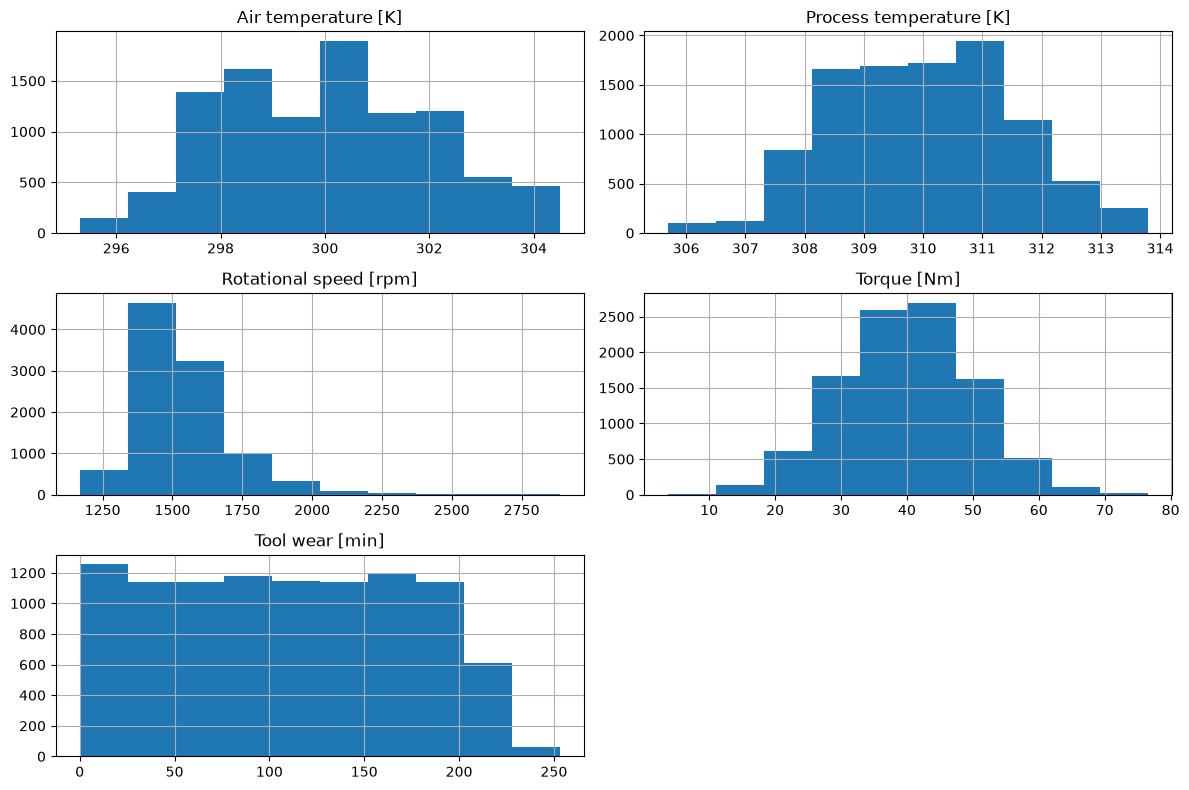

In [7]:
import matplotlib.pyplot as plt

numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numeric_cols].hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

# Initial Observations

- Air and process temperatures occupy relatively narrow ranges and
  appear to have broadly similar distributions.
- Rotational speed is right-skewed, with most observations concentrated
  near the lower end and relatively few high-speed observations.
- Torque has a roughly bell-shaped distribution centered around
  approximately 40 Nm.
- Tool wear is relatively evenly distributed through much of its range,
  with fewer observations above approximately 200 minutes.
- Further analysis is required to determine how these distributions
  differ between failure and non-failure observations.

In [13]:
numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df.groupby("Machine failure")[numeric_cols].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


In [12]:
df.groupby("Machine failure")[numeric_cols].median()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,300.0,310.0,1507.0,39.9,107.0
1,301.6,310.4,1365.0,53.7,165.0


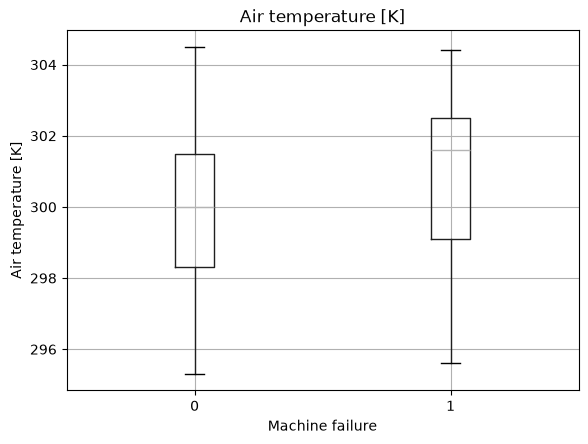

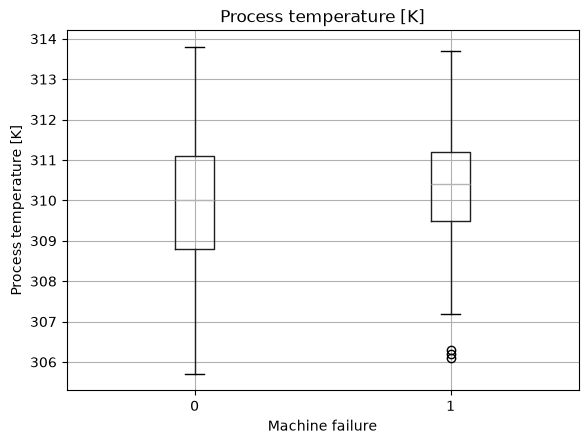

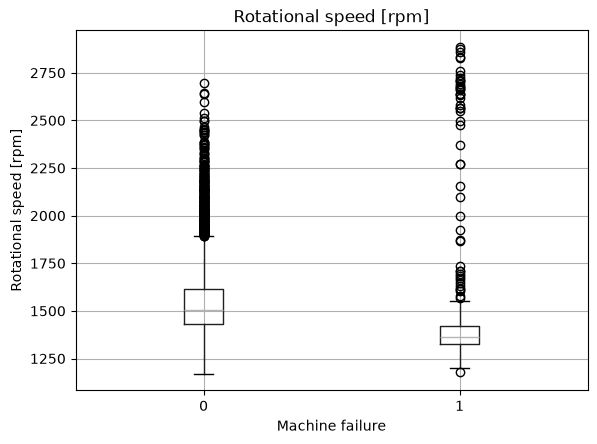

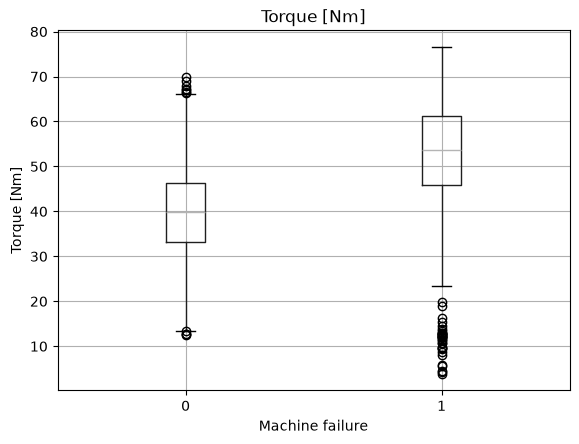

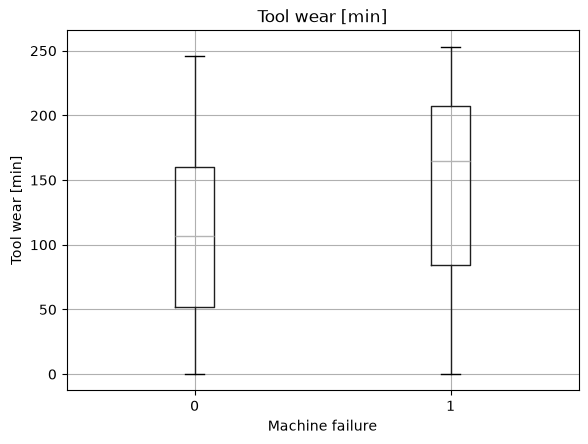

In [14]:
import matplotlib.pyplot as plt

for col in numeric_cols:
    df.boxplot(column=col, by="Machine failure")
    plt.title(col)
    plt.suptitle("")
    plt.xlabel("Machine failure")
    plt.ylabel(col)
    plt.show()

## Failure vs. Non-Failure Observations

Initial comparison of the numeric features showed several differences between
failure and non-failure observations:

- **Torque:** Failure observations generally had higher torque. Median torque
  was 53.7 Nm for failures compared with 39.9 Nm for non-failures. Some failure
  observations also occurred at unusually low torque values, suggesting the
  relationship may not be strictly linear.
- **Tool wear:** Failure observations generally had greater accumulated tool
  wear. Median tool wear was 165 minutes for failures compared with 107 minutes
  for non-failures.
- **Rotational speed:** Failure observations had a lower median rotational speed
  of 1,365 RPM compared with 1,507 RPM for non-failures. However, a number of
  failures also occurred at unusually high rotational speeds.
- **Air temperature:** Failure observations tended to have somewhat higher air
  temperatures, with a median of 301.6 K compared with 300.0 K for
  non-failures.
- **Process temperature:** The two groups showed relatively similar process
  temperatures, with medians of 310.4 K for failures and 310.0 K for
  non-failures.

These observations show associations within the dataset and do not establish
that any individual feature causes machine failure. Relationships between
multiple features should be examined next.

# Dataset limitation

The AI4I dataset does not provide longitudinal measurements showing machine conditions leading up to failure. Therefore, relationships between operating measurements and the failure label demonstrate statistical association within the dataset but do not by themselves establish that changes in those measurements precede failure. Claims about advance failure prediction should be limited accordingly.

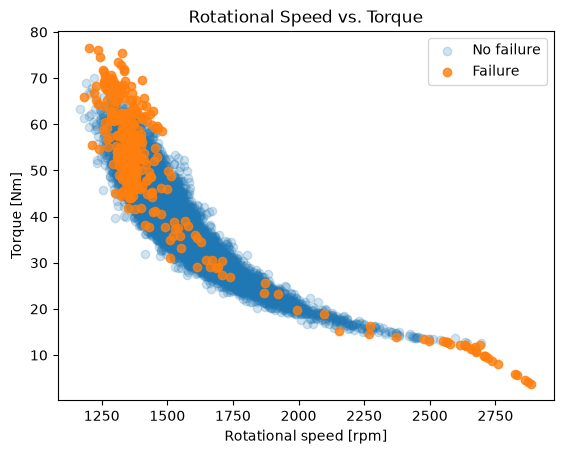

In [16]:
import matplotlib.pyplot as plt

normal = df[df["Machine failure"] == 0]
failure = df[df["Machine failure"] == 1]

plt.scatter(
    normal["Rotational speed [rpm]"],
    normal["Torque [Nm]"],
    alpha=0.2,
    label="No failure"
)

plt.scatter(
    failure["Rotational speed [rpm]"],
    failure["Torque [Nm]"],
    alpha=0.8,
    label="Failure"
)

plt.xlabel("Rotational speed [rpm]")
plt.ylabel("Torque [Nm]")
plt.title("Rotational Speed vs. Torque")
plt.legend()
plt.show()

# Rotational Speed and Torque

Rotational speed and torque exhibit a strong inverse relationship in the
dataset. Failure observations appear particularly concentrated at some of the
extremes of this relationship, including combinations of low rotational speed
with high torque and high rotational speed with low torque.

This relationship helps explain why comparisons based only on the mean or
median of individual features may obscure useful patterns. It also suggests
that interactions between features and nonlinear relationships may be
important when predicting machine failure.

Because the target classes are substantially imbalanced, the density of
failure and non-failure points in the scatterplot should not be interpreted
directly as failure probability.

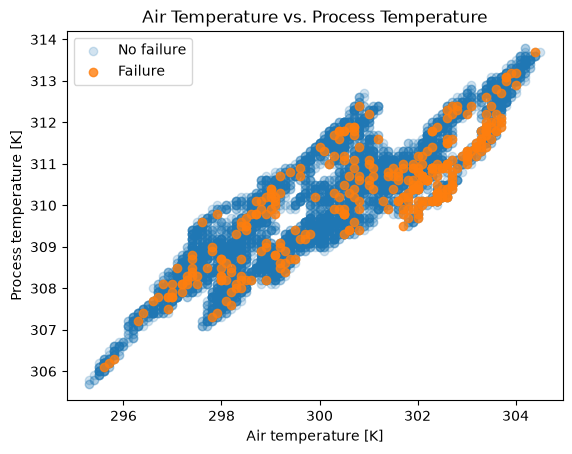

In [18]:
normal = df[df["Machine failure"] == 0]
failure = df[df["Machine failure"] == 1]

plt.scatter(
    normal["Air temperature [K]"],
    normal["Process temperature [K]"],
    alpha=0.2,
    label="No failure"
)

plt.scatter(
    failure["Air temperature [K]"],
    failure["Process temperature [K]"],
    alpha=0.8,
    label="Failure"
)

plt.xlabel("Air temperature [K]")
plt.ylabel("Process temperature [K]")
plt.title("Air Temperature vs. Process Temperature")
plt.legend()
plt.show()

In [17]:
correlation_cols = numeric_cols + ["Machine failure"]

correlation_matrix = df[correlation_cols].corr()

correlation_matrix

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


In [20]:
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df[failure_cols].sum()

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

In [21]:
df.groupby("Machine failure")[failure_cols].sum()

,TWF,HDF,PWF,OSF,RNF
Machine failure,,,,,
0,0,0,0,0,18
1,46,115,95,98,1


In [22]:
df[
    (df["Machine failure"] == 1) &
    (df[failure_cols].sum(axis=1) == 0)
]

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
1437,1438,H30851,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0
2749,2750,M17609,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
4044,4045,M18904,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0
4684,4685,M19544,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
5536,5537,M20396,M,302.3,311.8,1363,54.0,119,1,0,0,0,0,0
5941,5942,L53121,L,300.6,310.7,1438,48.5,78,1,0,0,0,0,0
6478,6479,L53658,L,300.5,309.8,1663,29.1,145,1,0,0,0,0,0
8506,8507,L55686,L,298.4,309.6,1710,27.3,163,1,0,0,0,0,0
9015,9016,L56195,L,297.2,308.1,1431,49.7,210,1,0,0,0,0,0


In [23]:
df[
    (df["Machine failure"] == 0) &
    (df[failure_cols].sum(axis=1) > 0)
]

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,M16081,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1
1302,1303,L48482,L,298.6,309.8,1505,45.7,144,0,0,0,0,0,1
1748,1749,H31162,H,298.4,307.7,1626,31.1,166,0,0,0,0,0,1
2072,2073,L49252,L,299.6,309.5,1570,35.5,189,0,0,0,0,0,1
2559,2560,L49739,L,299.3,309.0,1447,50.4,140,0,0,0,0,0,1
3065,3066,M17925,M,300.1,309.2,1687,27.7,95,0,0,0,0,0,1
3452,3453,H32866,H,301.6,310.5,1602,32.3,2,0,0,0,0,0,1
5471,5472,L52651,L,302.7,312.3,1346,61.2,170,0,0,0,0,0,1
5489,5490,L52669,L,302.6,312.1,1499,35.0,215,0,0,0,0,0,1
5495,5496,H34909,H,302.9,312.5,1357,55.0,12,0,0,0,0,0,1


# Feature Relationships and Failure Modes

Air temperature and process temperature are strongly positively correlated
(r = 0.876), while rotational speed and torque are strongly negatively
correlated (r = -0.875). Individual linear correlations between the operating
features and machine failure are relatively weak, with torque having the
largest observed positive correlation (r = 0.191).

Visual analysis indicates that these linear correlations do not capture all
of the structure in the data. In particular, failures occur at multiple
extremes of the rotational-speed/torque relationship, suggesting that feature
interactions and nonlinear relationships may be important.

The five specified failure modes occur 46 times for tool wear failure (TWF),
115 times for heat dissipation failure (HDF), 95 times for power failure
(PWF), 98 times for overstrain failure (OSF), and 19 times for random failure
(RNF).

The failure-mode labels do not correspond perfectly with the overall
`Machine failure` label. Nine observations are labeled as machine failures
without any of the five specific failure-mode indicators. Additionally, 18
observations have RNF = 1 while Machine failure = 0. The dataset documentation
should be consulted before interpreting these discrepancies.

In [24]:
failure_count = df[failure_cols].sum(axis=1)

failure_count.value_counts().sort_index()

0    9652
1     324
2      23
3       1
Name: count, dtype: int64

In [25]:
df[df[failure_cols].sum(axis=1) > 1][
    ["UDI", "Machine failure"] + failure_cols
]

,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
69,70,1,0,0,1,1,0
1324,1325,1,0,0,1,1,0
1496,1497,1,0,0,1,1,0
3611,3612,1,1,0,0,0,1
3854,3855,1,0,0,1,1,0
3943,3944,1,0,0,1,1,0
4254,4255,1,0,1,1,0,0
4342,4343,1,0,1,1,0,0
4370,4371,1,0,1,0,1,0
4383,4384,1,0,1,0,1,0


In [4]:
df[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
].agg(["min", "max"])

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
min,295.3,305.7,1168,3.8,0
max,304.5,313.8,2886,76.6,253
